<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_11_Fuzzy_RBDO_Cantilever_Benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# ME 640 — Optimum Design Methods
## Fuzzy Reliability-Based Design Optimization (Fuzzy RBDO)
### Lecture and Cantilever Beam Benchmark

This notebook follows the concepts and cantilever-beam formulation presented in the supplied ME 640 lecture material.

### Learning objectives

By the end of this lecture, you should be able to:

1. distinguish **probabilistic** and **fuzzy** representations of uncertainty;
2. define fuzzy sets, membership functions, and $\alpha$-cuts;
3. propagate fuzzy uncertainty by minimizing and maximizing a response at each $\alpha$-level;
4. construct a **Fuzzy Limit-State Function (FLSF)**;
5. interpret the fuzzy reliability index $\eta'$;
6. distinguish **safe**, **transient**, and **failure** fuzzy states;
7. formulate a fuzzy reliability-based optimization problem;
8. implement the cantilever-beam benchmark with fuzzy loads, Young's modulus, and yield strength;
9. compare nominal and fuzzy-reliable designs;
10. identify the advantages and limitations of fuzzy RBDO.

---

> ### Sign convention used in this notebook
>
> The supplied fuzzy-RBDO material defines the limit state as **demand minus resistance**:
>
> $$
> \mathrm{FLSF}=S-R.
> $$
>
> Therefore:
>
> $$
> \boxed{g<0:\text{ safe}},\qquad
> \boxed{g=0:\text{ limit state}},\qquad
> \boxed{g>0:\text{ failure}}.
> $$
>
> This is the opposite sign convention from the earlier FORM notebook, where $g=R-S$. Either convention is valid if used consistently.


### Primary Source:

Dourado, A.D., Lobato, F.S., Cavalini, A.A. et al. Fuzzy Reliability-Based Optimization for Engineering System Design. Int. J. Fuzzy Syst. 21, 1418–1429 (2019) [doi:10.1007/s40815-019-00655-5](https://doi.org/10.1007/s40815-019-00655-5)

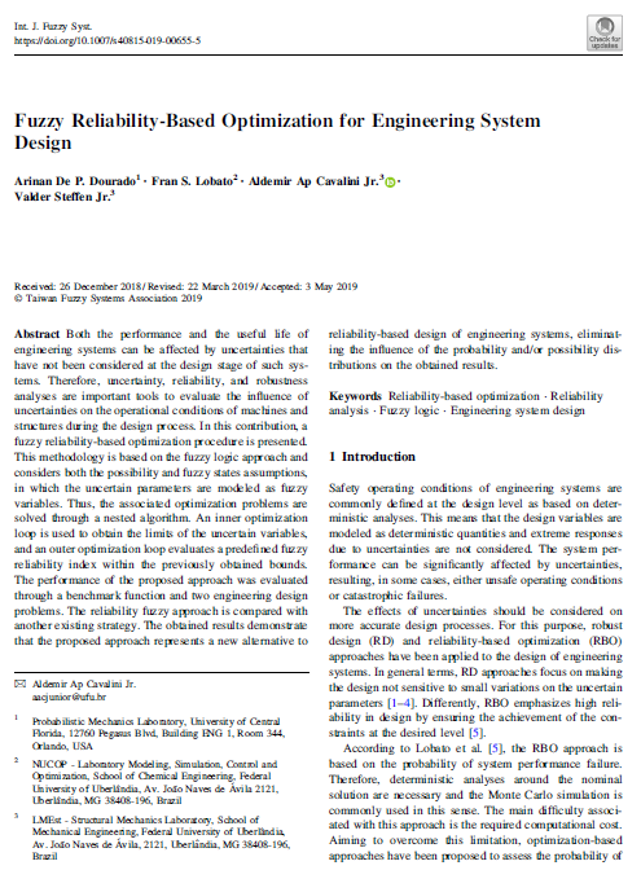

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, differential_evolution

np.random.seed(640)
plt.rcParams["figure.figsize"] = (7.5, 5.2)
plt.rcParams["font.size"] = 11



# 1. Why fuzzy uncertainty?

Conventional reliability analysis usually represents uncertain quantities as random variables with probability distributions:

$$
X\sim f_X(x).
$$

This is appropriate when sufficient data or a defensible probabilistic model is available. In early-stage engineering design, however, uncertainty may instead arise from:

- sparse measurements;
- manufacturing tolerances;
- expert judgment;
- poorly characterized operating conditions;
- incomplete knowledge of material properties;
- uncertain distribution parameters.

In these situations, assigning a precise probability distribution can imply more statistical knowledge than is actually available.

A **fuzzy set** provides an alternative representation of imprecise or epistemic uncertainty. A fuzzy variable $\tilde X$ is characterized by a membership function

$$
\mu_{\tilde X}(x)\in[0,1].
$$

The membership value expresses the degree to which a particular value is compatible with the fuzzy description.

### Probability versus membership

A membership function is **not a probability density**:

- its integral does not need to equal one;
- membership does not represent frequency of occurrence;
- $\mu=0.8$ does not mean an 80% probability.

Fuzzy methods therefore answer a different question from probabilistic reliability analysis.



# 2. Triangular fuzzy variables

A convenient engineering representation is the triangular fuzzy number

$$
\tilde X=(x_L,x_N,x_R),
$$

where

- $x_L$ = lower support,
- $x_N$ = nominal/modal value,
- $x_R$ = upper support.

Its membership function is

$$
\mu_{\tilde X}(x)=
\begin{cases}
0, & x<x_L,\\[2mm]
\dfrac{x-x_L}{x_N-x_L}, & x_L\le x\le x_N,\\[3mm]
\dfrac{x_R-x}{x_R-x_N}, & x_N\le x\le x_R,\\[3mm]
0, & x>x_R.
\end{cases}
$$

The nominal value has membership one, while the support limits have membership zero.


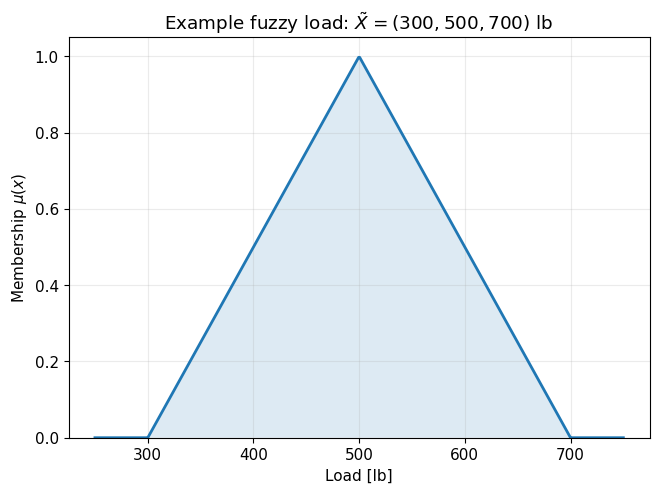

In [ ]:
def triangular_membership(x, left, nominal, right):
    x=np.asarray(x)
    mu=np.zeros_like(x,dtype=float)
    a=(x>=left)&(x<=nominal)
    b=(x>=nominal)&(x<=right)
    mu[a]=(x[a]-left)/(nominal-left)
    mu[b]=(right-x[b])/(right-nominal)
    return np.clip(mu,0,1)

x=np.linspace(250,750,500)
mu=triangular_membership(x,300,500,700)

fig,ax=plt.subplots()
ax.plot(x,mu,lw=2)
ax.fill_between(x,0,mu,alpha=.15)
ax.set(xlabel="Load [lb]",ylabel=r"Membership $\mu(x)$",
       title=r"Example fuzzy load: $\tilde X=(300,500,700)$ lb")
ax.set_ylim(0,1.05); ax.grid(alpha=.25)
plt.show()



# 3. $\alpha$-cuts: converting a fuzzy set into nested intervals

At a selected membership level $\alpha$, the fuzzy variable is represented by the interval

$$
X_\alpha=
\{x:\mu_{\tilde X}(x)\ge\alpha\}.
$$

For a triangular fuzzy number,

$$
\boxed{
X_\alpha=
\left[
x_L+\alpha(x_N-x_L),\;
x_R-\alpha(x_R-x_N)
\right]
}
$$

with $0\le\alpha\le1$.

Thus:

- $\alpha=0$: the complete support is considered;
- $0<\alpha<1$: an intermediate uncertainty interval is considered;
- $\alpha=1$: the interval collapses to the nominal value.

The nested intervals provide the computational basis for fuzzy uncertainty propagation.


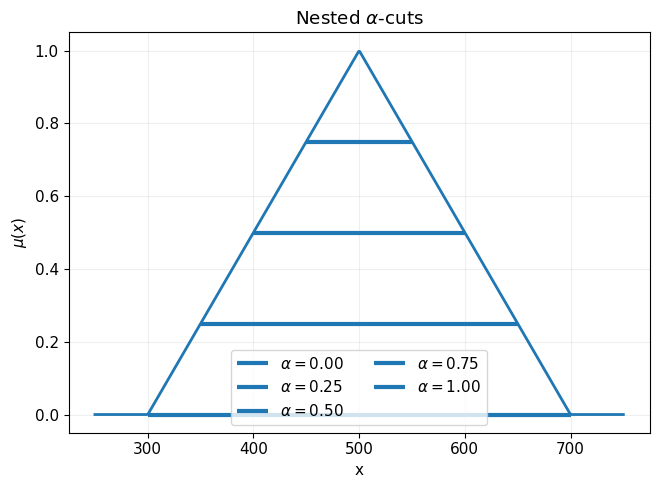

In [ ]:
def alpha_cut(tri, alpha):
    left,nominal,right=tri
    return (left+alpha*(nominal-left),
            right-alpha*(right-nominal))

tri=(300,500,700)
xx=np.linspace(250,750,500)
fig,ax=plt.subplots()
ax.plot(xx,triangular_membership(xx,*tri),lw=2)
for a in [0.0,0.25,0.50,0.75,1.0]:
    lo,hi=alpha_cut(tri,a)
    ax.hlines(a,lo,hi,lw=3,label=fr"$\alpha={a:.2f}$")
ax.set(xlabel="x",ylabel=r"$\mu(x)$",title=r"Nested $\alpha$-cuts")
ax.legend(ncol=2); ax.grid(alpha=.2)
plt.show()



# 4. Fuzzy uncertainty propagation

Suppose the engineering response is

$$
z=f(\tilde x_1,\tilde x_2,\ldots,\tilde x_n).
$$

At each $\alpha_k$, the uncertain inputs define a bounded region

$$
\mathbf X_{\alpha_k}.
$$

Two optimization problems are solved:

$$
\boxed{
z_L(\alpha_k)=
\min_{\mathbf x\in\mathbf X_{\alpha_k}} f(\mathbf x)
}
$$

and

$$
\boxed{
z_R(\alpha_k)=
\max_{\mathbf x\in\mathbf X_{\alpha_k}} f(\mathbf x)
}
$$

The pair

$$
[z_L(\alpha_k),z_R(\alpha_k)]
$$

defines the response interval at that $\alpha$-level.

Repeating this process over all $\alpha$-levels reconstructs the fuzzy response.

### Computational interpretation

$$
\boxed{
\text{Fuzzy inputs}
\rightarrow
\alpha\text{-cuts}
\rightarrow
\min/\max\text{ optimization}
\rightarrow
\text{response envelopes}
}
$$

This is one of the central ideas of the supplied lecture material: fuzzy propagation can be performed through repeated deterministic optimization rather than random sampling.


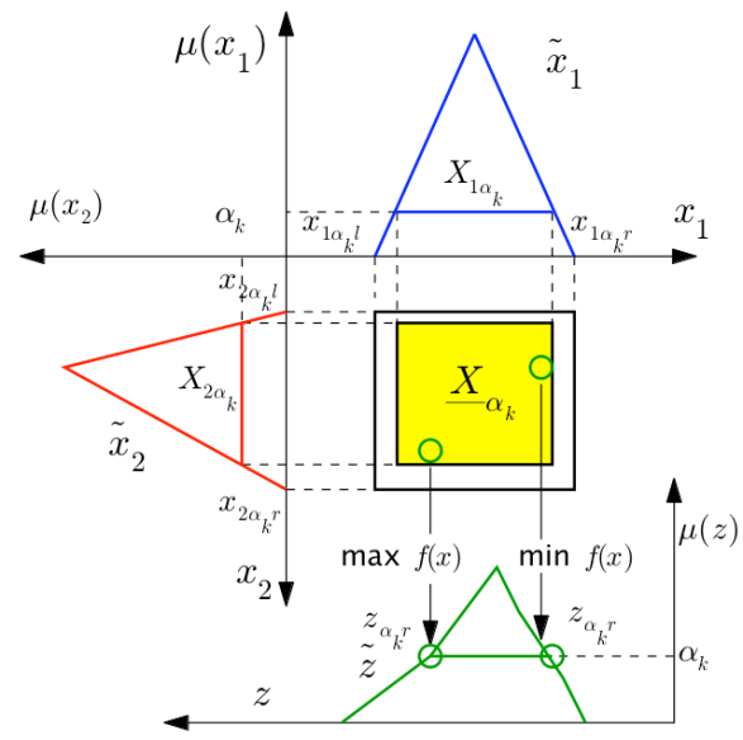

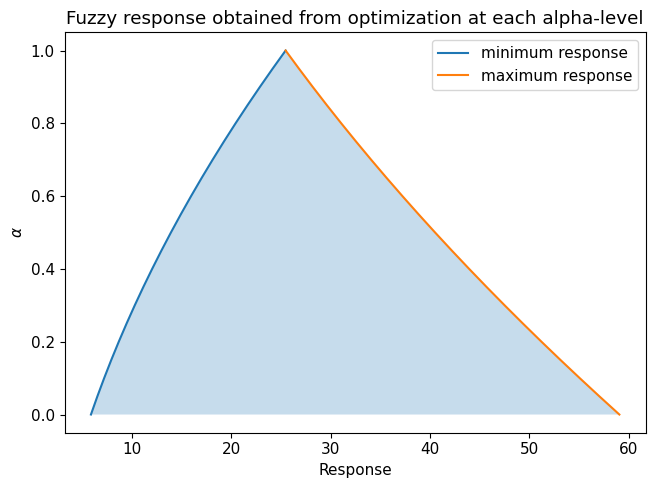

In [ ]:
# Simple nonlinear illustration
X1=(3,5,7)
X2=(1.5,3,4.5)

def response(v):
    x1,x2=v
    return (x1-1.5)**2 + 0.8*x2**2 + 0.4*x1*x2

alphas=np.linspace(0,1,21)
lower=[]; upper=[]
for a in alphas:
    b1=alpha_cut(X1,a); b2=alpha_cut(X2,a)
    bounds=[b1,b2]
    rmin=differential_evolution(response,bounds,seed=640,polish=True)
    rmax=differential_evolution(lambda q:-response(q),bounds,seed=640,polish=True)
    lower.append(rmin.fun)
    upper.append(-rmax.fun)

fig,ax=plt.subplots()
ax.fill_betweenx(alphas,lower,upper,alpha=.25)
ax.plot(lower,alphas,label="minimum response")
ax.plot(upper,alphas,label="maximum response")
ax.set(xlabel="Response",ylabel=r"$\alpha$",
       title="Fuzzy response obtained from optimization at each alpha-level")
ax.legend(); plt.show()



# 5. Fuzzy limit-state function

For reliability analysis, the engineering constraint is expressed through a **Fuzzy Limit-State Function (FLSF)**.

Using the sign convention of the supplied material,

$$
\boxed{\mathrm{FLSF}=S-R=g(\mathbf x)}
$$

where $S$ represents demand and $R$ resistance.

At every $\alpha$-level, fuzzy propagation gives

$$
\mathrm{FLSF}'_{\alpha}
=
\left[
\mathrm{FLSF}'_L,\;
\mathrm{FLSF}'_R
\right].
$$

The location of this interval relative to zero determines the reliability state:

### Safe state

$$
\mathrm{FLSF}'_L<0,
\qquad
\mathrm{FLSF}'_R<0.
$$

All admissible values at that $\alpha$-level satisfy the constraint.

### Transient state

$$
\mathrm{FLSF}'_L<0<
\mathrm{FLSF}'_R.
$$

The fuzzy interval contains both safe and failed realizations.

### Failure state

$$
0<\mathrm{FLSF}'_L<
\mathrm{FLSF}'_R.
$$

All admissible values violate the constraint.



# 6. Fuzzy reliability index $\eta'$

The supplied formulation defines a normalized fuzzy reliability index using the lower FLSF bound and the width of the fuzzy response interval:

$$
\boxed{
\eta'
=
\frac{\mathrm{FLSF}'_L}
{
\mathrm{FLSF}'_R-\mathrm{FLSF}'_L
}
}
$$

for a nonzero interval width.

This gives a convenient geometric measure of where the zero limit-state boundary lies relative to the fuzzy response interval.

For the convention used here:

$$
\begin{array}{lll}
\eta'>0
&\Rightarrow&
\text{failure domain},\\[2mm]
-1<\eta'\le0
&\Rightarrow&
\text{transient domain},\\[2mm]
\eta'\le-1
&\Rightarrow&
\text{safety domain}.
\end{array}
$$

In particular,

$$
\boxed{\eta'=-1}
$$

corresponds to the upper fuzzy limit-state bound reaching zero:

$$
\mathrm{FLSF}'_R=0.
$$

This becomes a natural active constraint for minimum-size fuzzy RBDO.


In [ ]:
def fuzzy_eta(gL,gR,tol=1e-12):
    width=gR-gL
    # width=abs(gR-gL)
    # if width<tol:
    #     if gR<0: return -np.inf
    #     if gL>0: return np.inf
    #     return -1.0
    return gL/width

examples=pd.DataFrame({
    "Case":["Safe","Boundary","Transient","Failure"],
    "FLSF_L":[-10,-10,-5,2],
    "FLSF_R":[-3,0,4,8]
})
examples["eta_prime"]=[fuzzy_eta(a,b) for a,b in zip(examples.FLSF_L,examples.FLSF_R)]
display(examples)


,Case,FLSF_L,FLSF_R,eta_prime
0,Safe,-10,-3,-1.428571
1,Boundary,-10,0,-1.000000
2,Transient,-5,4,-0.555556
3,Failure,2,8,0.333333



# 7. Fuzzy RBDO formulation

A conventional RBDO problem minimizes an objective while requiring a target probabilistic reliability index.

The fuzzy counterpart can instead constrain the fuzzy reliability measure:

$$
\begin{aligned}
\min_{\mathbf d}\quad & f(\mathbf d)\\
\text{s.t.}\quad&
\eta'_j(\mathbf d)\le\eta'_{j,\mathrm{target}},
\qquad j=1,\ldots,m.
\end{aligned}
$$

For complete safety over the fuzzy support,

$$
\eta'_{j,\mathrm{target}}=-1,
$$

which is equivalent to requiring

$$
\boxed{
\mathrm{FLSF}'_{jR}\le0
}
$$

for every constraint.

This formulation is particularly useful when the available uncertainty information is better represented as bounded fuzzy quantities than as precisely calibrated probability distributions.



# 8. Cantilever beam benchmark

We now implement the cantilever-beam problem.
The rectangular beam has two design variables:

$$
x_{d1}=b,\qquad x_{d2}=h,
$$

where $b$ and $h$ are cross-sectional dimensions.

The objective is minimum cross-sectional area:

$$
\boxed{
\min_{b,h} f(b,h)=bh
}
$$

Four quantities are treated as fuzzy variables:

| Variable | Physical meaning | Nominal | Lower | Upper |
|---|---|---:|---:|---:|
| $x_{f1}$ | horizontal load $X$ [lb] | 500 | 300 | 700 |
| $x_{f2}$ | vertical load $Y$ [lb] | 1000 | 800 | 1200 |
| $x_{f3}$ | Young's modulus $E$ [psi] | $29\times10^6$ | $26.1\times10^6$ | $31.9\times10^6$ |
| $x_{f4}$ | yield strength $R$ [psi] | 40000 | 36000 | 44000 |

These fuzzy supports as corresponding to the $2\sigma$ ranges of the probabilistic comparison problem.


In [ ]:
# Triangular fuzzy variables from the supplied benchmark
X_f = (300.0, 500.0, 700.0)             # horizontal load [lb]
Y_f = (800.0, 1000.0, 1200.0)           # vertical load [lb]
E_f = (26.1e6, 29.0e6, 31.9e6)          # Young's modulus [psi]
R_f = (36000.0, 40000.0, 44000.0)       # yield strength [psi]

fuzzy_table=pd.DataFrame({
    "Variable":["X load [lb]","Y load [lb]","E [psi]","Yield strength [psi]"],
    "Lower":[X_f[0],Y_f[0],E_f[0],R_f[0]],
    "Nominal":[X_f[1],Y_f[1],E_f[1],R_f[1]],
    "Upper":[X_f[2],Y_f[2],E_f[2],R_f[2]]
})
display(fuzzy_table)


,Variable,Lower,Nominal,Upper
0,X load [lb],300.0,500.0,700.0
1,Y load [lb],800.0,1000.0,1200.0
2,E [psi],26100000.0,29000000.0,31900000.0
3,Yield strength [psi],36000.0,40000.0,44000.0



# 9. Cantilever limit-state functions

The benchmark contains two constraints.

## LSF1 — stress at the fixed end

The equivalent bending stress must remain below yield strength:

$$
\boxed{
g_1=
\frac{600Y}{bh^2}
+
\frac{600X}{b^2h}
-
R
}
$$

where $X$ and $Y$ are the two transverse loads and $R$ is yield strength.

Safety requires

$$
g_1\le0.
$$

## LSF2 — tip displacement

The tip displacement must remain below the allowable displacement \(d_0\):

$$
\boxed{
g_2=
\frac{4L^3}{Ebh}
\sqrt{
\left(\frac{Y}{h^2}\right)^2+
\left(\frac{X}{b^2}\right)^2
}
-d_0
}
$$

with

$$
L=100\;\mathrm{in},
\qquad
d_0=2.2535\;\mathrm{in}.
$$

Again,

$$
g_2\le0
$$

defines safety.

The fuzzy forms are obtained by replacing $X,Y,E,R$ with their fuzzy counterparts and calculating the lower and upper extrema at each $\alpha$-level.


In [ ]:
L = 100.0       # in
d0 = 2.2535     # in

def g_stress(design, X, Y, R):
    b,h=design
    return 600*Y/(b*h**2) + 600*X/(b**2*h) - R

def g_displacement(design, X, Y, E):
    b,h=design
    return (4*L**3/(E*b*h)
            *np.sqrt((Y/h**2)**2+(X/b**2)**2)
            - d0)

# Nominal illustration
trial=np.array([4.0,4.5])
print("At b=4.0, h=4.5:")
print("g1 nominal =",g_stress(trial,X_f[1],Y_f[1],R_f[1]))
print("g2 nominal =",g_displacement(trial,X_f[1],Y_f[1],E_f[1]))


At b=4.0, h=4.5:
g1 nominal = -28425.925925925927
g2 nominal = -1.8056851180246412



# 10. Fuzzy propagation for the cantilever

For each design $(b,h)$ and each $\alpha$-level, calculate

$$
g_{jL}(\alpha)
=
\min_{\mathbf x\in X_\alpha}g_j
$$

and

$$
g_{jR}(\alpha)
=
\max_{\mathbf x\in X_\alpha}g_j.
$$

For these particular limit states, monotonicity lets us obtain the extrema directly.

### Stress

$$
g_1=
\frac{600Y}{bh^2}
+\frac{600X}{b^2h}-R.
$$

Therefore $g_1$ increases with $X$ and $Y$ and decreases with $R$. Thus:

$$
g_{1R}
=
g_1(X_U,Y_U,R_L),
$$

$$
g_{1L}
=
g_1(X_L,Y_L,R_U).
$$

### Displacement

$$
g_2=
\frac{4L^3}{Ebh}
\sqrt{
\left(\frac{Y}{h^2}\right)^2+
\left(\frac{X}{b^2}\right)^2
}
-d_0.
$$

It increases with the loads and decreases with $E$. Therefore:

$$
g_{2R}=g_2(X_U,Y_U,E_L),
$$

$$
g_{2L}=g_2(X_L,Y_L,E_U).
$$

This analytical monotonicity eliminates the need for a numerical inner min/max optimizer for this benchmark, while preserving the same $\alpha$-cut logic.


In [ ]:
def fuzzy_bounds(design, alpha=0.0):
    XL,XU=alpha_cut(X_f,alpha)
    YL,YU=alpha_cut(Y_f,alpha)
    EL,EU=alpha_cut(E_f,alpha)
    RL,RU=alpha_cut(R_f,alpha)

    g1L=g_stress(design,XL,YL,RU)
    g1R=g_stress(design,XU,YU,RL)

    g2L=g_displacement(design,XL,YL,EU)
    g2R=g_displacement(design,XU,YU,EL)

    return g1L,g1R,g2L,g2R

def fuzzy_indices(design,alpha=0.0):
    g1L,g1R,g2L,g2R=fuzzy_bounds(design,alpha)
    return fuzzy_eta(g1L,g1R),fuzzy_eta(g2L,g2R)

trial=[4.0,4.5]
print("alpha=0 bounds:",fuzzy_bounds(trial,0))
print("eta values:",fuzzy_indices(trial,0))


alpha=0 bounds: (-35574.07407407407, -21277.777777777777, np.float64(-1.9488684799449087), np.float64(-1.6263437420520597))
eta values: (-2.488341968911917, np.float64(-6.042539535656866))



# 11. Visualizing fuzzy limit-state envelopes

Before optimizing the design, inspect how the two FLSFs evolve with $\alpha$.

The $\alpha=0$ interval contains the broadest uncertainty range. As $\alpha\rightarrow1$, the interval contracts toward the nominal response.

A design that is fully safe over the support satisfies

$$
g_{jR}(0)\le0.
$$


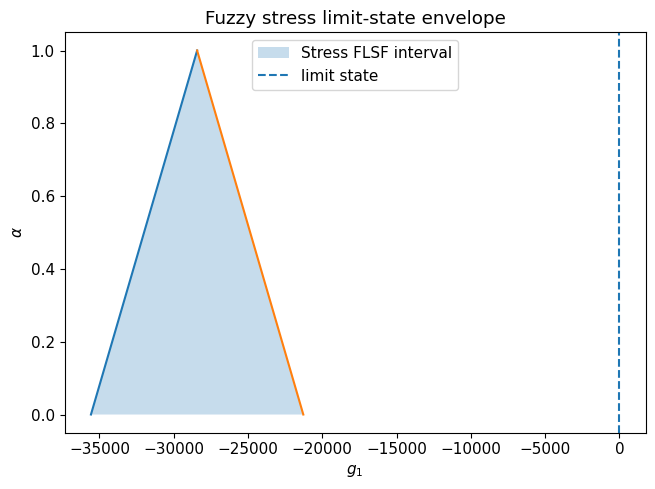

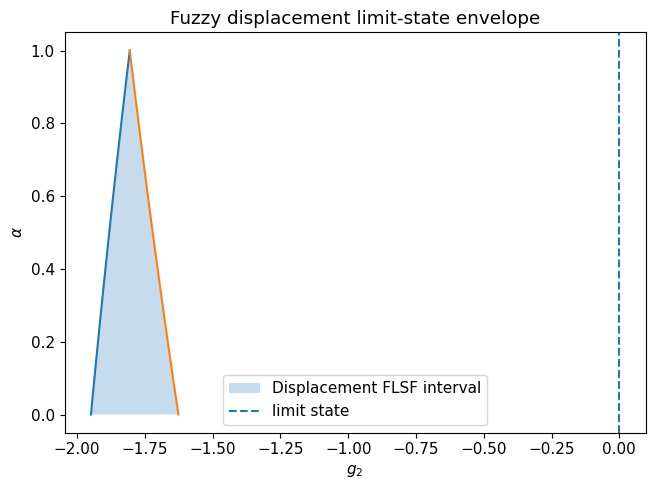

In [ ]:
alphas=np.linspace(0,1,51)
trial=[4.0,4.5]
arr=np.array([fuzzy_bounds(trial,a) for a in alphas])

fig,ax=plt.subplots()
ax.fill_betweenx(alphas,arr[:,0],arr[:,1],alpha=.25,label="Stress FLSF interval")
ax.plot(arr[:,0],alphas); ax.plot(arr[:,1],alphas)
ax.axvline(0,ls="--",label="limit state")
ax.set(xlabel=r"$g_1$",ylabel=r"$\alpha$",title="Fuzzy stress limit-state envelope")
ax.legend(); plt.show()

fig,ax=plt.subplots()
ax.fill_betweenx(alphas,arr[:,2],arr[:,3],alpha=.25,label="Displacement FLSF interval")
ax.plot(arr[:,2],alphas); ax.plot(arr[:,3],alphas)
ax.axvline(0,ls="--",label="limit state")
ax.set(xlabel=r"$g_2$",ylabel=r"$\alpha$",title="Fuzzy displacement limit-state envelope")
ax.legend(); plt.show()



# 12. Fuzzy RBDO of the cantilever beam

The fuzzy optimization problem is

$$
\boxed{
\begin{aligned}
\min_{b,h}\quad & bh\\
\text{s.t.}\quad&
\eta'_1(b,h)\le-1,\\
&\eta'_2(b,h)\le-1.
\end{aligned}
}
$$

For this benchmark, requiring $\eta'_j\le-1$ is equivalent to requiring the upper fuzzy limit-state bounds to remain nonpositive:

$$
g_{1R}(0)\le0,
\qquad
g_{2R}(0)\le0.
$$

Hence the optimizer seeks the smallest beam whose **worst response over the complete fuzzy support** satisfies both constraints.


In [ ]:
def area(z):
    return z[0]*z[1]

def worst_g1(z):
    return fuzzy_bounds(z,0.0)[1]

def worst_g2(z):
    return fuzzy_bounds(z,0.0)[3]

constraints=[
    {"type":"ineq","fun":lambda z:-worst_g1(z)},
    {"type":"ineq","fun":lambda z:-worst_g2(z)}
]

result=minimize(
    area,
    x0=[4.0,4.6],
    method="SLSQP",
    bounds=[(0.5,10.0),(0.5,10.0)],
    constraints=constraints,
    options={"ftol":1e-12,"maxiter":2000,"disp":False}
)

b_opt,h_opt=result.x
g1L,g1R,g2L,g2R=fuzzy_bounds(result.x,0)
eta1,eta2=fuzzy_indices(result.x,0)

b_ira,h_ira=2.45,3.89
g1L_ira,g1R_ira,g2L_ira,g2R_ira=fuzzy_bounds(np.array([b_ira,h_ira]),0)
eta1_ira,eta2_ira=fuzzy_indices(np.array([b_ira,h_ira]),0)

b_ppt,h_ppt=4.05,4.63
g1L_ppt,g1R_ppt,g2L_ppt,g2R_ppt=fuzzy_bounds(np.array([b_ppt,h_ppt]),0)
eta1_ppt,eta2_ppt=fuzzy_indices(np.array([b_ppt,h_ppt]),0)

summary=pd.DataFrame({
    "Quantity":["b","h","Area","FLSF1_L","FLSF1_R","eta1","FLSF2_L","FLSF2_R","eta2"],
    "Value":[b_opt,h_opt,area(result.x),g1L,g1R,eta1,g2L,g2R,eta2],
    "Reference#1":[b_ira,h_ira,area(np.array([b_ira,h_ira])),g1L_ira,g1R_ira,eta1_ira,g2L_ira,g2R_ira,eta2_ira],
    "Reference#2":[b_ppt,h_ppt,area(np.array([b_ppt,h_ppt])),g1L_ppt,g1R_ppt,eta1_ppt,g2L_ppt,g2R_ppt,eta2_ppt]
})
display(summary)
print("Optimization success:",result.success)
print(result.message)


,Quantity,Value,Reference#1,Reference#2
0,b,2.387616e+00,2.450000,4.050000
1,h,4.093056e+00,3.890000,4.630000
2,Area,9.772648e+00,9.530500,18.751500
3,FLSF1_L,-2.428571e+04,-23343.926976,-36101.103874
4,FLSF1_R,7.275958e-11,1408.168063,-22176.505181
5,eta1,-1.000000e+00,-0.943109,-2.592614
6,FLSF2_L,-1.341723e+00,-1.296303,-1.975588
7,FLSF2_R,-2.417382e-02,0.014302,-1.678195
8,eta2,-1.018348e+00,-0.989088,-6.643007


Optimization success: False
Positive directional derivative for linesearch



# 13. Expected benchmark behavior

References reports a fuzzy solution approximately

$$
x_{d1}=4.0452,\qquad
x_{d2}=4.6314,
$$

with objective

$$
f=x_{d1}x_{d2}\approx18.73.
$$

It also reports approximately

$$
\mathrm{FLSF}'_{1L}=-36100,\qquad
\mathrm{FLSF}'_{1R}=-23344,
$$

and

$$
\eta'_1\approx-2.59,
$$

while the displacement constraint is:

$$
\mathrm{FLSF}'_{2R}\approx-1.68,
\qquad
\eta'_2\approx-6.64.
$$

Small numerical differences can result from optimizer tolerances and implementation details.

In [ ]:
reference=pd.DataFrame({
    "Quantity":["b","h","Area","eta1","eta2"],
    "Reference":[b_ppt,h_ppt,area(np.array([b_ppt,h_ppt])),eta1_ppt,eta2_ppt],
    "Notebook":[b_opt,h_opt,area(result.x),eta1,eta2]
})
reference["Difference"]=reference["Notebook"]-reference["Reference"]
display(reference)


,Quantity,Reference,Notebook,Difference
0,b,4.050000,2.387616,-1.662384
1,h,4.630000,4.093056,-0.536944
2,Area,18.751500,9.772648,-8.978852
3,eta1,-2.592614,-1.000000,1.592614
4,eta2,-6.643007,-1.018348,5.624659



# 15. Nominal optimization versus fuzzy RBDO

To see the effect of uncertainty, solve the same beam-sizing problem using only nominal values:

$$
X=500,\quad
Y=1000,\quad
E=29\times10^6,\quad
R=40000.
$$

The nominal optimization requires only

$$
g_1^{nom}\le0,\qquad
g_2^{nom}\le0.
$$

It does **not** guarantee feasibility when the fuzzy variables move away from their nominal values.


In [ ]:
def nominal_g1(z):
    return g_stress(z,X_f[1],Y_f[1],R_f[1])
def nominal_g2(z):
    return g_displacement(z,X_f[1],Y_f[1],E_f[1])

nom=minimize(
    area,[3,4],
    method="SLSQP",
    bounds=[(.5,10),(.5,10)],
    constraints=[
        {"type":"ineq","fun":lambda z:-nominal_g1(z)},
        {"type":"ineq","fun":lambda z:-nominal_g2(z)}
    ],
    options={"ftol":1e-12,"maxiter":2000}
)

comparison=pd.DataFrame({
    "Design":["Nominal optimum","Fuzzy RBDO"],
    "b":[nom.x[0],b_opt],
    "h":[nom.x[1],h_opt],
    "Area":[area(nom.x),area(result.x)],
    "Worst fuzzy g1":[worst_g1(nom.x),worst_g1(result.x)],
    "Worst fuzzy g2":[worst_g2(nom.x),worst_g2(result.x)]
})
display(comparison)


,Design,b,h,Area,Worst fuzzy g1,Worst fuzzy g2
0,Nominal optimum,2.352034,3.326278,7.823520,1.449223e+04,1.011172
1,Fuzzy RBDO,2.387616,4.093056,9.772648,7.275958e-11,-0.024174


The comparison illustrates the central fuzzy-RBDO tradeoff:

$$
\boxed{
\text{smaller nominal design}
\quad\longleftrightarrow\quad
\text{larger design with protection against imprecision}
}
$$

The fuzzy design is not larger because fuzzy logic inherently “adds safety.” It is larger because the optimization requires the constraints to remain satisfied over the specified uncertainty support.


# 16. Design-space visualization

We can visualize the worst-case fuzzy constraints directly.

The fuzzy-feasible region satisfies

$$
g_{1R}(0)\le0
$$

and

$$
g_{2R}(0)\le0.
$$

The minimum-area solution occurs where the objective contours first touch this reliable region.


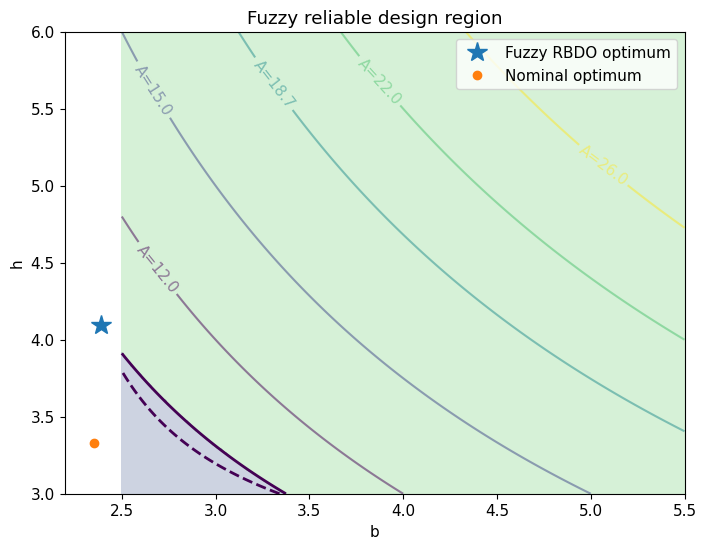

In [ ]:
bs=np.linspace(2.5,5.5,160)
hs=np.linspace(3.0,6.0,160)
B,H=np.meshgrid(bs,hs)
G1=np.zeros_like(B); G2=np.zeros_like(B)
for i in range(B.shape[0]):
    for j in range(B.shape[1]):
        G1[i,j]=worst_g1([B[i,j],H[i,j]])
        G2[i,j]=worst_g2([B[i,j],H[i,j]])

fig,ax=plt.subplots(figsize=(8,6))
safe=(G1<=0)&(G2<=0)
ax.contourf(B,H,safe.astype(float),levels=[-.5,.5,1.5],alpha=.25)
c1=ax.contour(B,H,G1,levels=[0],linewidths=2)
c2=ax.contour(B,H,G2,levels=[0],linewidths=2,linestyles="--")
A=B*H
ca=ax.contour(B,H,A,levels=[12,15,18.73,22,26],alpha=.5)
ax.clabel(ca,fmt="A=%.1f")
ax.plot(b_opt,h_opt,"*",ms=15,label="Fuzzy RBDO optimum")
ax.plot(nom.x[0],nom.x[1],"o",label="Nominal optimum")
ax.set(xlabel="b",ylabel="h",title="Fuzzy reliable design region")
ax.legend(); plt.show()


# 17. Evolution of the optimized design's FLSFs

At the final fuzzy-RBDO solution, examine the entire $\alpha$-level response rather than only the $\alpha=0$ constraint.

Because the uncertainty intervals contract toward their nominal values, the FLSF intervals also contract as $\alpha$ increases.


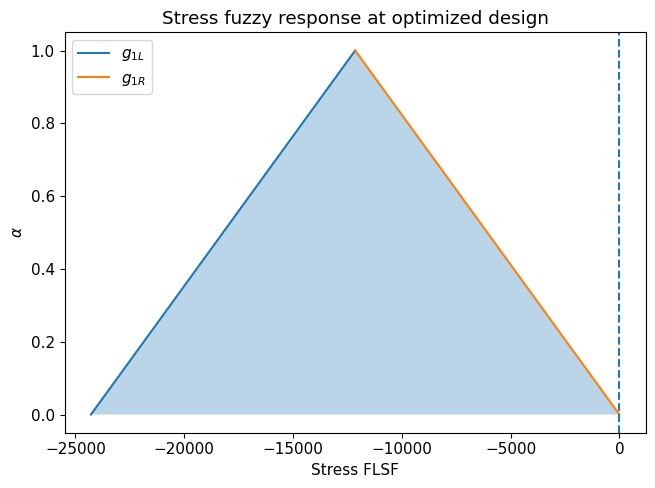

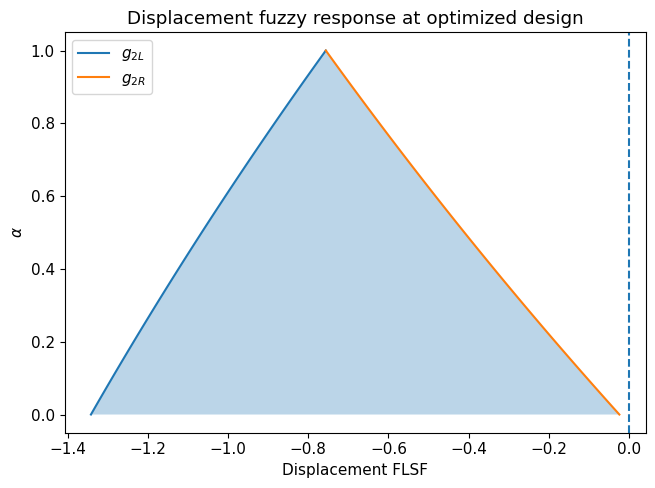

In [ ]:
arr=np.array([fuzzy_bounds(result.x,a) for a in alphas])

fig,ax=plt.subplots()
ax.fill_betweenx(alphas,arr[:,0],arr[:,1],alpha=.3)
ax.plot(arr[:,0],alphas,label=r"$g_{1L}$")
ax.plot(arr[:,1],alphas,label=r"$g_{1R}$")
ax.axvline(0,ls="--")
ax.set(xlabel="Stress FLSF",ylabel=r"$\alpha$",title="Stress fuzzy response at optimized design")
ax.legend();plt.show()

fig,ax=plt.subplots()
ax.fill_betweenx(alphas,arr[:,2],arr[:,3],alpha=.3)
ax.plot(arr[:,2],alphas,label=r"$g_{2L}$")
ax.plot(arr[:,3],alphas,label=r"$g_{2R}$")
ax.axvline(0,ls="--")
ax.set(xlabel="Displacement FLSF",ylabel=r"$\alpha$",title="Displacement fuzzy response at optimized design")
ax.legend();plt.show()



# 18. Why use fuzzy RBDO?

### Advantages

**1. Limited statistical information**

Fuzzy uncertainty can be useful when only nominal values and plausible bounds are available.

**2. Explicit representation of epistemic uncertainty**

It avoids automatically treating lack of knowledge as random variability.

**3. No large Monte Carlo sample is inherently required**

For low-dimensional monotonic problems such as this beam, extrema can be calculated efficiently.

**4. Natural integration with optimization**

At each $\alpha$-level, fuzzy propagation is formulated as deterministic min/max optimization.

**5. Transparent worst-case interpretation**

The designer can directly see how the uncertain support maps into lower and upper response envelopes.

---

# 19. Limitations and disadvantages

**1. Membership functions must be specified**

Their support, shape, and nominal/core values can involve engineering judgment.

**2. Membership is not probability**

A fuzzy reliability index cannot automatically be interpreted as a probability of failure.

**3. Conservatism**

Requiring safety over the entire $\alpha=0$ support can yield substantially larger designs.

**4. Computational expense for complex systems**

General fuzzy propagation can require two optimization problems for every response, constraint, $\alpha$-level, and design iteration.

**5. Correlation/dependence is not automatically represented**

Dependencies among fuzzy variables require deliberate modeling.

**6. Model uncertainty remains**

Fuzzy treatment of parameters does not remove uncertainty or bias in the physical model itself.


# 20. Probabilistic RBDO versus fuzzy RBDO

| Aspect | Probabilistic RBDO | Fuzzy RBDO |
|---|---|---|
| Uncertainty representation | Probability distributions | Membership functions / fuzzy intervals |
| Typical uncertainty | Aleatory variability | Epistemic / imprecise information |
| Reliability measure | $P_f$, $\beta$ | FLSF interval, $\eta'$, possibility-based measures |
| Propagation | FORM, Monte Carlo, etc. | $\alpha$-cuts + min/max optimization |
| Interpretation | Frequency/probability | Plausibility / interval compatibility |
| Data demand | Distribution estimation may require data | Can work with bounds/expert information |
| Main risk | Wrong distribution/model | Subjective membership/support |
| Potential conservatism | Depends on target $P_f$ | Can be high for full-support safety |

The methods should therefore be viewed as different representations of uncertainty—not as interchangeable numerical algorithms.



# 21. Optional extension: changing the protected $\alpha$-level

The benchmark above requires safety over the complete fuzzy support $alpha=0$.

As an instructional extension, solve

$$
g_{jR}(\alpha^*)\le0
$$

for different $\alpha^*$.

This demonstrates how the design changes when protection is required only over increasingly central portions of the fuzzy set.

**Caution:** $\alpha^*$ is not a probability or confidence level.


/tmp/ipykernel_1652/3160496784.py:8: RuntimeWarning: divide by zero encountered in scalar divide
  return gL/width


,alpha,b,h,Area,eta_1,eta_2
0,0.0,2.387616,4.093056,9.772648,-1.000000,-1.018348
1,0.1,2.354829,4.057197,9.554004,-1.000000,-1.000000
2,0.2,2.348486,3.976357,9.338420,-1.000000,-1.000000
3,0.3,2.343640,3.894078,9.126318,-1.000000,-1.000000
4,0.4,2.340881,3.809607,8.917837,-1.000000,-1.000000
5,0.5,2.341187,3.721737,8.713282,-1.000000,-1.000000
6,0.6,2.346362,3.628299,8.513302,-1.000000,-1.000000
7,0.7,2.360449,3.524529,8.319470,-1.000000,-1.000000
8,0.8,2.397586,3.394024,8.137462,-1.000000,-1.000000
9,0.9,2.386972,3.343072,7.979818,-1.094256,-1.000000


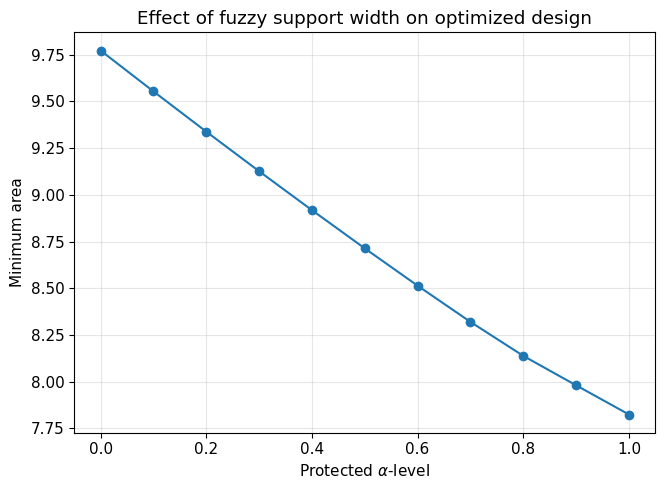

In [ ]:
def optimize_at_alpha(alpha):
    def wg1(z): return fuzzy_bounds(z,alpha)[1]
    def wg2(z): return fuzzy_bounds(z,alpha)[3]
    return minimize(
        area,[4,4.5],method="SLSQP",
        bounds=[(.5,10),(.5,10)],
        constraints=[
            {"type":"ineq","fun":lambda z:-wg1(z)},
            {"type":"ineq","fun":lambda z:-wg2(z)}
        ],
        options={"ftol":1e-11,"maxiter":1000}
    )

rows=[]
for a in np.linspace(0,1,11):
    rr=optimize_at_alpha(a)
    eta_a1,eta_a2=fuzzy_indices(rr.x,a)
    rows.append([a,*rr.x,area(rr.x),eta_a1,eta_a2])
alpha_designs=pd.DataFrame(rows,columns=["alpha","b","h","Area","eta_1","eta_2"])
display(alpha_designs)

fig,ax=plt.subplots()
ax.plot(alpha_designs.alpha,alpha_designs.Area,marker="o")
ax.set(xlabel=r"Protected $\alpha$-level",ylabel="Minimum area",
       title="Effect of fuzzy support width on optimized design")
ax.grid(alpha=.3);plt.show()



# 22. Summary

The fuzzy-RBDO workflow developed in this lecture is

$$
\boxed{
\begin{array}{c}
\text{Define fuzzy uncertain variables}\\
\downarrow\\
\text{Construct }\alpha\text{-cuts}\\
\downarrow\\
\min/\max\text{ each limit-state function}\\
\downarrow\\
[\mathrm{FLSF}'_L,\mathrm{FLSF}'_R]\\
\downarrow\\
\text{Evaluate }\eta'\\
\downarrow\\
\text{Classify safe/transient/failure}\\
\downarrow\\
\text{Optimize design subject to fuzzy reliability}
\end{array}}
$$

For the cantilever benchmark:

- $b$ and $h$ are design variables;
- two loads, $E$, and yield strength are fuzzy;
- stress and displacement are the two FLSFs;
- full-support safety requires the upper FLSF bounds to remain below zero;
- the displacement constraint controls the fuzzy optimum;
- fuzzy RBDO produces a larger design than nominal optimization because it protects against the specified imprecision.

### Discussion questions

1. Why is the fuzzy reliability index $\eta'$ not directly comparable to FORM's $\beta$?
2. Why does $\eta'=-1$ correspond to the safe/transient boundary in this formulation?
3. Why can the beam FLSF extrema be calculated analytically rather than using an inner optimizer?
4. What would change if a limit-state function were non-monotonic?
5. Is the $\alpha=0$ fuzzy design necessarily “better” than a probabilistic RBDO design?
6. How should the fuzzy support limits be justified in a real engineering application?
